# Analysis Pipeline

In this notebook we analyse the quality of the ScArches mapping using the *MappingAccessment* package. 

### Library Imports

In [1]:
# os.chdir('../')
import warnings
import os
from os.path import abspath
import importlib

import scanpy as sc
import anndata
import matplotlib.pyplot as plt
import numpy as np

import datetime
import statsmodels.stats.multitest as mtc
from MappingAssessment import MapAnalyzer, Plotter


### General settings

In [2]:
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

DATA_DIR = abspath(os.path.join(os.getcwd(), os.pardir, 'data'))
os.makedirs('Results', exist_ok=True)
RESULTS_DIR = os.path.join(os.getcwd(), 'Results')

In [3]:
adata = sc.read(f'{DATA_DIR}/HLCA_full_v1.1_emb.h5ad')

In [4]:
adata.obs.core_or_extension

CGATGTAAGTTACGGG_SC10                               core
cc05p_CATGCCTGTGTGCCTG_carraro_csmc            extension
ATTCTACCAAGGTTCT_HD68                               core
D062_TGACCCTTCAAACCCA-sub_wang_sub_batch3      extension
muc9826_GTCGTGAGAGGA_mayr                      extension
                                                 ...    
TTGTGGATCGTTCCTG_5-PX5-sub_mould               extension
TCAGGATCAAGACGTG_F02526                             core
CAACCTCTCATGTAGC-WSSS8015042-0_meyer_unpubl    extension
022C-b_GGATGTTTCCAAGTAC_adams                  extension
145I-a_GTCGTAACAGTAGAGC_adams                  extension
Name: core_or_extension, Length: 2282447, dtype: category
Categories (2, object): ['core', 'extension']

### Set arguments for `AdataHandler` object

In [5]:
core_datasets = set(
    adata[
        adata.obs.core_or_extension == "core"].obs["dataset"].cat.categories
)

extension_datasets = set(
    adata[
        adata.obs.core_or_extension == "extension"].obs["dataset"].cat.categories
)

# Common datasets in "Core" and "Extension"
common_core_extension = core_datasets.intersection(extension_datasets)

# Subset a sample "extension" dataset that is not present in "core".
unique_extension_datasets = extension_datasets - common_core_extension 
unique_extension_datasets

{'Budinger_2020',
 'Duong_lungMAP_unpubl',
 'Eils_2020',
 'Gomperts2021_UCLA',
 'Gomperts_2021_CFF',
 'Gomperts_2021_CSMC',
 'Janssen_2020',
 'Kaminski_2020',
 'Lafyatis_2019',
 'Lambrechts_2021',
 'MeyerNikolic_unpubl_UCL',
 'Meyer_2021_3prime',
 'Meyer_2021_5prime',
 'Peer_Massague_2020',
 'Regev_2021_Cryo',
 'Regev_2021_Fresh',
 'Regev_2021_Nuclei',
 'Schiller_2020',
 'Schiller_2021',
 'Schultze_unpubl',
 'Shalek_2018',
 'Sheppard_2020',
 'Sims_2019',
 'Sun_2020_batch1',
 'Sun_2020_batch2',
 'Sun_2020_batch3',
 'Sun_2020_batch4',
 'Tata_unpubl',
 'Thienpont_2018_10Xv1',
 'Thienpont_2018_10Xv2',
 'Wunderink_2021_cryo',
 'Wunderink_2021_fresh',
 'Xu_2020_LAM1_3',
 'Zhang_2021'}

Select query dataset from "Extensions".

In [6]:
query_dataset = "Meyer_2021_5prime"

In [7]:
dataset = query_dataset
ident = query_dataset 
query_color = "Blue"
condition = "X"
exclude = []

In [8]:
adata = adata[(adata.obs.core_or_extension=="core")|((adata.obs.dataset==dataset))]

### Preprocessing

Set clean cell labels on all levels and one label-column for transfer from curated metadata. 

In [9]:
# In case that no umap based on the embedding is calculated, recalculate the UMAP
# sc.pp.neighbors(adata, n_neighbors=50, n_pcs=30)
# sc.tl.umap(adata)

Initialize *AdataHandler* object. The *AdataHandler* makes sure all columns are named a standarized way. It also is able to perform a label transfer to the query.

In [10]:
adata_handler = MapAnalyzer.AdataHandler(
    adata,
    workspace = RESULTS_DIR,
    ident = ident + "/",  # folder that indentifies this workpartition
    log = True,  # create a logfile
)

Logger directory already exists


In [11]:
# Plotter object for the plots
plotter = Plotter.MapPlot(workspace = f"{adata_handler.workspace}/{ident}")

In [12]:
adata_handler.standarize_columns(
    condition_name=condition,  # condition name we want to distinguish
    query_dataset=dataset,  # query datasets
    cell_type_col=None,  # column name denoting celltype, none if no unified column
    dataset_col="dataset",  # column name denoting dataset
    sample_col="sample",  # column name denoting sample
    condition_col="lung_condition",  # column name denoting condition (abovementioned)
    subject_col="donor_id",  # column name denoting patients, subjects or donors
    disease_exclude=exclude,  # diseases to exclude from analysis
)

2023-06-17 16:21:57.114876	Standarizing columns...
2023-06-17 16:22:00.067804	No cell_type column set. Please make sure to run 'set_cell_type_levels' to obtain a unified cell type column 'cell_label'.
2023-06-17 16:22:00.069563	Finished column standarizing



Set appropriate levels for the cell type annotation.

In [13]:
adata_handler.set_cell_type_levels(
    connect_threshold = 1, 
    annotation_columns = ['ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5'],
    finest_level_column = "ann_finest_level",
    unlabeled_tag = "nan")

2023-06-17 16:22:01.994455	starting with cell labels:
['AT0', 'AT1', 'AT2', 'AT2 proliferating', 'Adventitial fibroblasts', 'Alveolar Mph CCL3+', 'Alveolar Mph MT-positive', 'Alveolar Mph proliferating', 'Alveolar fibroblasts', 'Alveolar macrophages', 'B cells', 'Basal resting', 'CD4 T cells', 'CD8 T cells', 'Classical monocytes', 'Club (nasal)', 'Club (non-nasal)', 'DC1', 'DC2', 'Deuterosomal', 'EC aerocyte capillary', 'EC arterial', 'EC general capillary', 'EC venous pulmonary', 'EC venous systemic', 'Goblet (bronchial)', 'Goblet (nasal)', 'Goblet (subsegmental)', 'Hematopoietic stem cells', 'Hillock-like', 'Interstitial Mph perivascular', 'Ionocyte', 'Lymphatic EC differentiating', 'Lymphatic EC mature', 'Lymphatic EC proliferating', 'Mast cells', 'Mesothelium', 'Migratory DCs', 'Monocyte-derived Mph', 'Multiciliated (nasal)', 'Multiciliated (non-nasal)', 'Myofibroblasts', 'NK cells', 'Neuroendocrine', 'Non-classical monocytes', 'Peribronchial fibroblasts', 'Pericytes', 'Plasma cell

In [14]:
adata = adata_handler.get_adata()

Transfer celltype labels from reference data to query cells.

In [15]:
adata_handler.transfer_labels(transfer_columns=["cell_label"], pickle=False)

2023-06-17 16:24:04.855780	Transferring labels...
2023-06-17 16:24:05.618878	Train KNNModel
Weighted KNN with n_neighbors = 50 ... 2023-06-17 16:24:05.795873	transferring cell_label
finished!


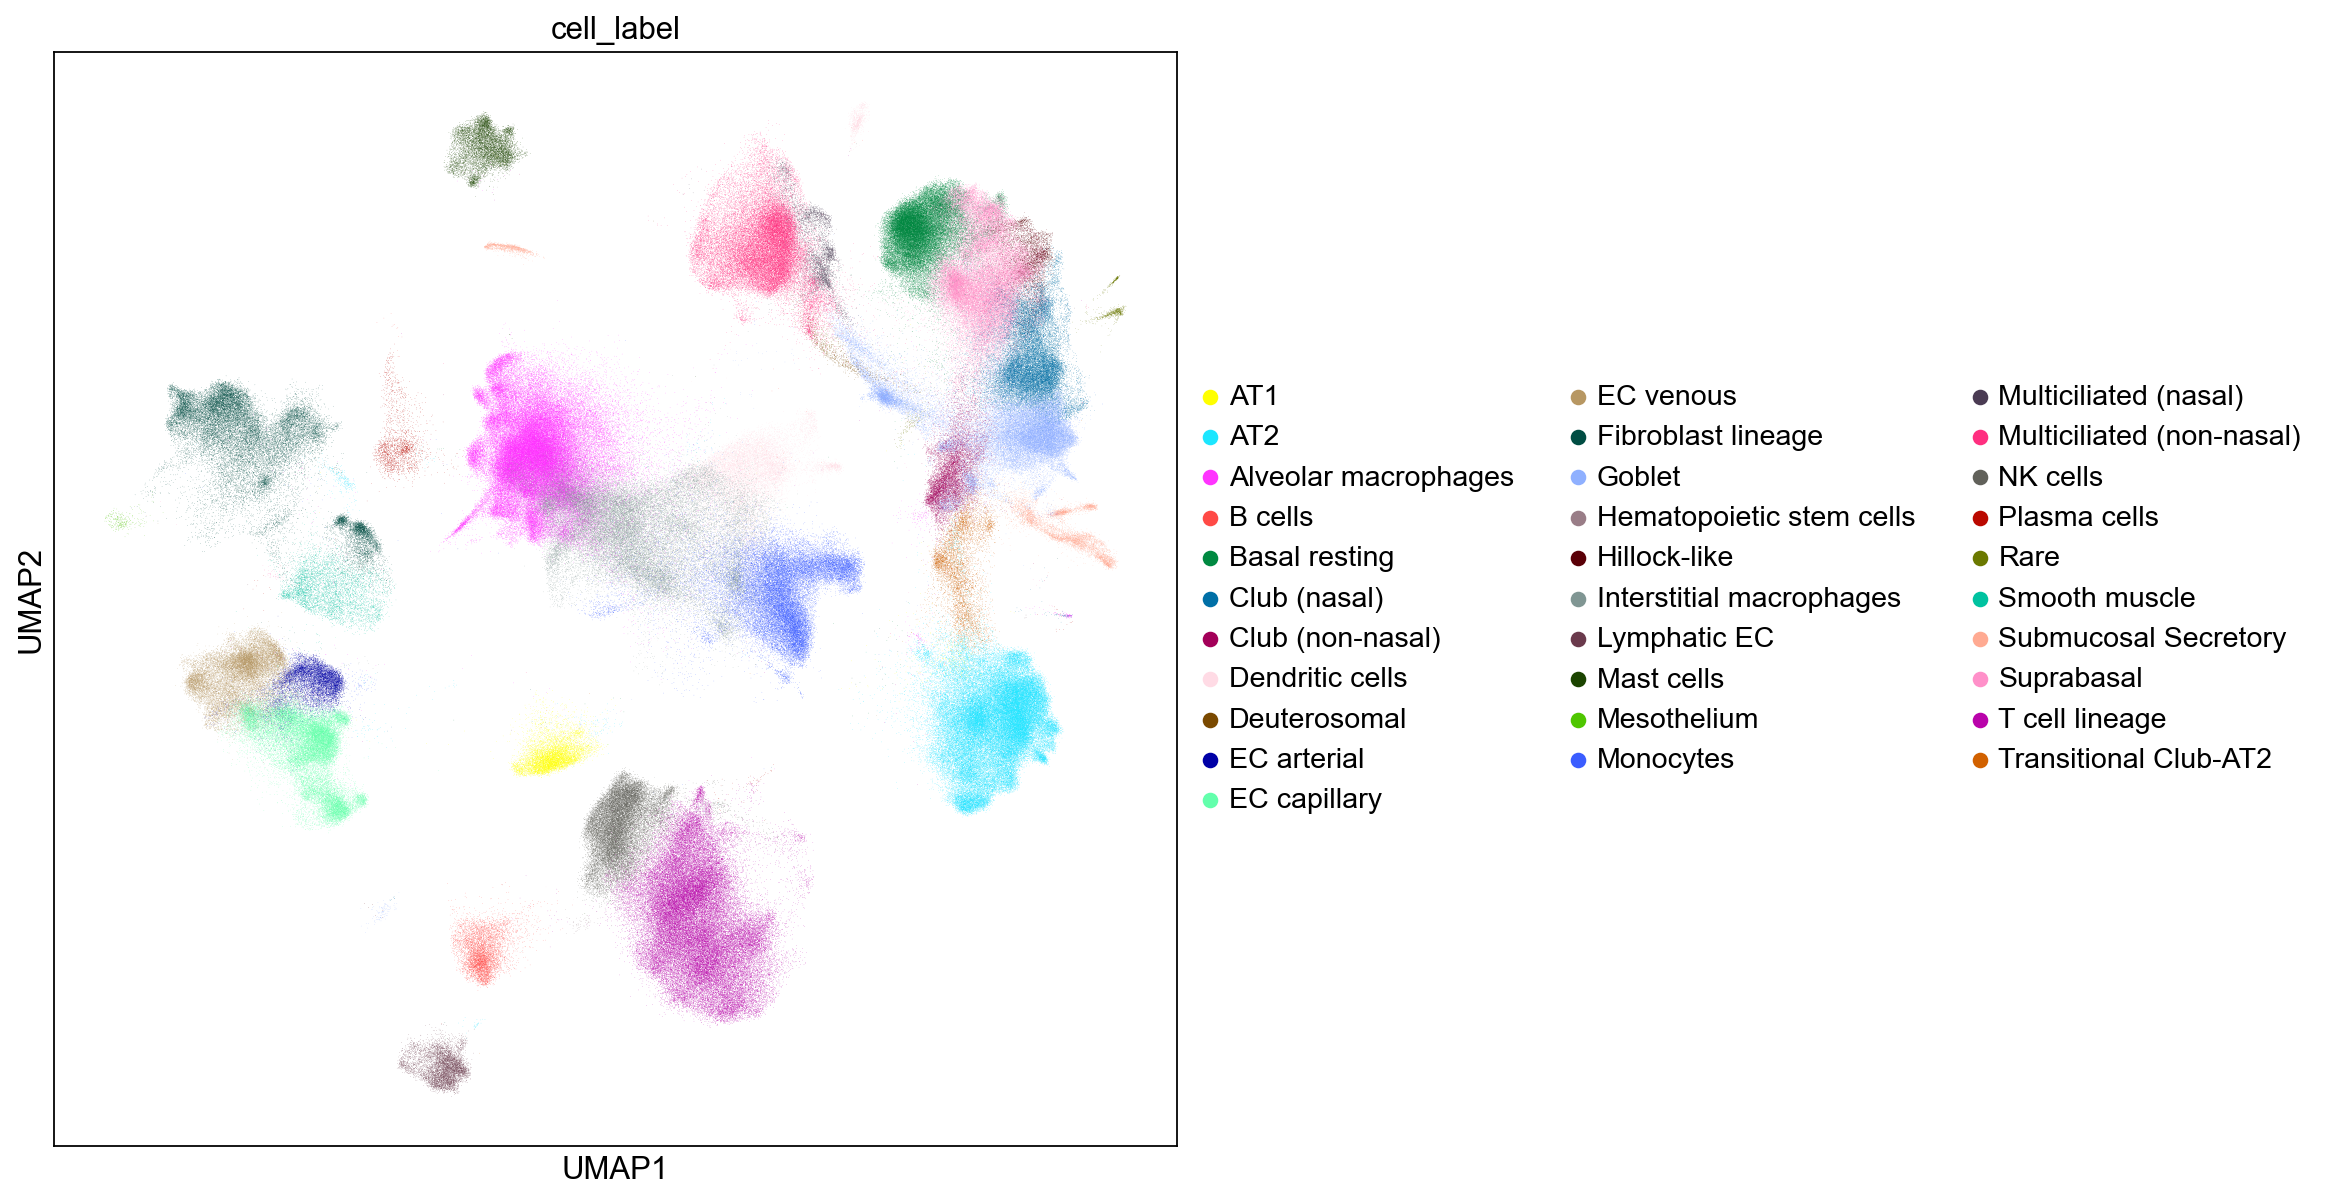

In [16]:
sc.pl.umap(adata, color="cell_label")

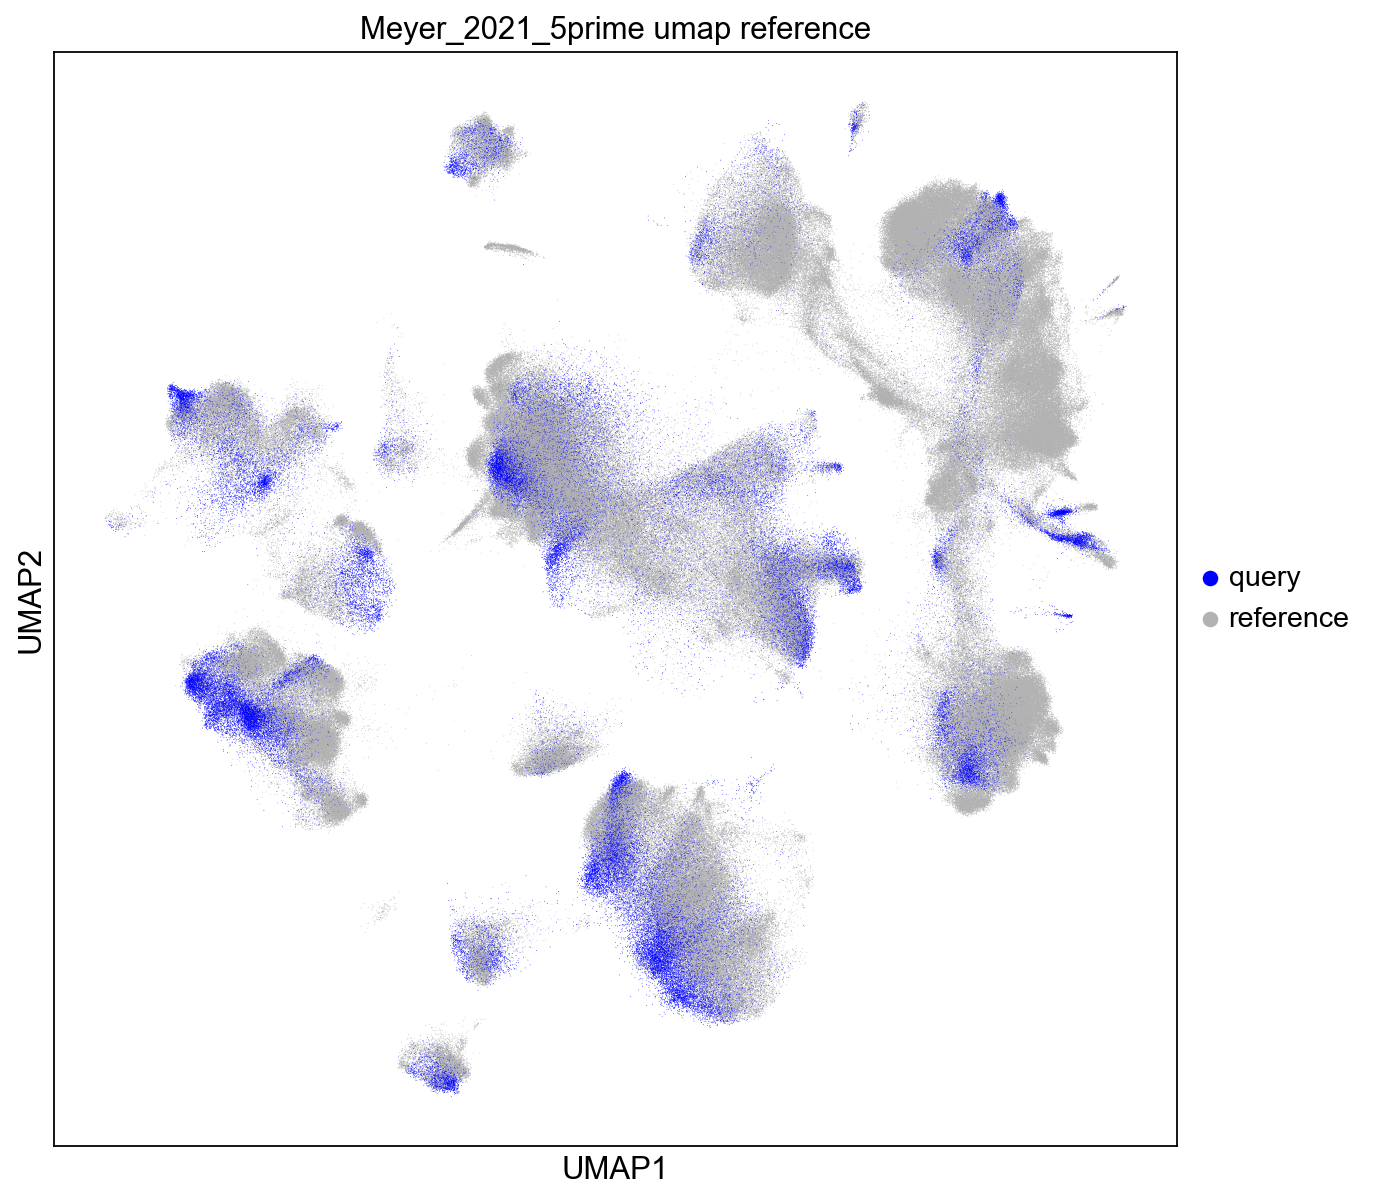

In [17]:
plotter.plot_umap(
    adata=adata, color_query=query_color, title_stub=ident, mode="reference", save=False
)

### Main Pipeline

Initialize the *MappingScoring* object. Pass the *AdataHandler* so that adata and workspace information is passed on.

In [18]:
scorer = MapAnalyzer.MappingScoring(adata_handler)

Logger directory already exists


In [19]:
adata = scorer.get_adata()

#### Calculate query mixing scores

In [20]:
# Opt 1: add scores from disc 
# scorer.add_scores(
#     os.path.join(scorer.workspace, ident, 'scores.csv')
# )

# Opt 2: compute scores
scorer.calculate_mixing_scores(
    adata = adata,
    verbose = False,
    save = True,
)

100%|██████████| 31/31 [10:58<00:00, 21.25s/it]


### Calculate baseline

To compare our mapping to a upper bound, we calculate the scores for the integrated reference. For that we set one sample to query, while the other samples are set to reference (excluding the real query). By that we achieve a baseline for each celltype of how well different samples are integrated. We then can compare out mapping scores to the baseline to see, wether the mapping is of comparable quality to the integration. 

In [21]:
# Opt 1: add baseline from disc
# scorer.add_baseline(
#     os.path.join(scorer.workspace, 'baseline.csv'),
#     os.path.join(RESULTS_DIR, 'MapAnalyzer_Results_3.0', 'celltypes.txt')
# )

# Opt 2: compute baseline
scorer.calculate_baseline(
    verbose = False,
    save = False,
)

100%|██████████| 31/31 [00:17<00:00,  1.72it/s]


Add correction model for score correction for sample size.

In [22]:
# Option 1: add score transform from disc
# scorer.add_transformation(os.path.join(RESULTS_DIR, 'MapAnalyzer_Results_3.0', 'transformation.csv'))

# Option 2: compute transformation
scorer.calculate_transformation(
    save = True
)

### Analyzing the Mapping with MapAnalyzer

In [23]:
adata = scorer.get_adata()

In [24]:
scorer.analyze_mapping()

2023-06-17 18:18:56.697532	Correcting the for sample size...
2023-06-17 18:19:01.054016	5841STDY7991475: ['AT2', 'Alveolar macrophages', 'Dendritic cells', 'EC arterial', 'Fibroblast lineage', 'Interstitial macrophages', 'Mast cells', 'Monocytes', 'Multiciliated (non-nasal)', 'NK cells', 'T cell lineage']
2023-06-17 18:19:01.343949	Correcting the for sample size...
2023-06-17 18:19:05.482114	5841STDY7991476: ['Dendritic cells', 'Fibroblast lineage', 'Mast cells', 'Multiciliated (non-nasal)', 'NK cells', 'T cell lineage']
2023-06-17 18:19:05.766572	Correcting the for sample size...
2023-06-17 18:19:09.760197	5841STDY7991477: ['Dendritic cells', 'Interstitial macrophages', 'Mast cells', 'Monocytes', 'NK cells', 'T cell lineage']
2023-06-17 18:19:10.123072	Correcting the for sample size...
2023-06-17 18:19:14.122522	5841STDY7991478: ['Dendritic cells', 'EC arterial', 'Fibroblast lineage', 'Interstitial macrophages', 'Mast cells', 'Monocytes', 'Multiciliated (non-nasal)', 'NK cells', 'T ce

In [25]:
scorer.sample_report

health_status excluded        fraction accepted
                          first      sum count                   
sample                                                           
5841STDY7991475         healthy        1    11  0.090909     True
5841STDY7991476         healthy        0     6  0.000000     True
5841STDY7991477         healthy        0     6  0.000000     True
5841STDY7991478         healthy        1     9  0.111111     True
5841STDY7991479         healthy        1     7  0.142857     True
5841STDY7991482         healthy        0    10  0.000000     True
5841STDY7991483         healthy        1     5  0.200000     True
5841STDY7991484         healthy        0     7  0.000000     True
5841STDY7991485         healthy        0     9  0.000000     True
5841STDY7991486         healthy        0     9  0.000000     True
5841STDY7991487         healthy        1     8  0.125000     True
WSSS8015042             healthy        0     6  0.000000     True
WSSS8015043             healthy        0     8  0.000000     True
WSSS8015044             healthy        1     8  0.125000     True
WSSS8015045             healthy        0     9  0.000000     True
WSSS8015046             healthy        0     8  0.000000     True
WSSS8015047             healthy        0    10  0.000000     True
WSSS8015048             healthy        0    10  0.000000     True
WSSS8015049             healthy        0    14  0.000000     True
WSSS8015050             healthy        0    11  0.000000     True
WSSS8015051             healthy        0    10  0.000000     True
WSSS8062679             healthy        4    12  0.333333    False
WSSS8062680             healthy        1    13  0.076923     True
WSSS8062681             healthy        1    11  0.090909     True
WSSS8062682             healthy        1    12  0.083333     True
WSSS8123922             healthy        0     5  0.000000     True
WSSS8123923             healthy        0     6  0.000000     True
WSSS8123924             healthy        0     1  0.000000     True
WSSS8123925             healthy        0     4  0.000000     True
WSSS8123926             healthy        0    11  0.000000     True
WSSS8123927             healthy        0    12  0.000000     True
WSSS8123928             healthy        0     6  0.000000     True
WSSS8123929             healthy        0     8  0.000000     True
WSSS8123930             healthy        0    12  0.000000     True
WSSS8123931             healthy        1    10  0.100000     True
WSSS_A_LNG8620059       healthy        0     9  0.000000     True
WSSS_A_LNG8620060       healthy        0     6  0.000000     True
WSSS_A_LNG8620061       healthy        0     9  0.000000     True
WSSS_A_LNG8620062       healthy        0     8  0.000000     True
WSSS_A_LNG8620063       healthy        0     9  0.000000     True
WSSS_A_LNG8620064       healthy        0     8  0.000000     True
WSSS_A_LNG8620065       healthy        0     6  0.000000     True
WSSS_A_LNG8620066       healthy        0     7  0.000000     True
WSSS_A_LNG8620067       healthy        0     3  0.000000     True
WSSS_A_LNG8620068       healthy        0     4  0.000000     True

In [26]:
scorer.report.to_csv(
    os.path.join(RESULTS_DIR, 'report.csv')
)

### Plotting the outcomes

In [27]:
report = scorer.report.loc

In [28]:
adata = adata[adata.obs.cell_label.isin(scorer.cell_types)]

In [29]:
adata

View of AnnData object with n_obs × n_vars = 535594 × 30
    obs: 'suspension_type', 'subject_ID', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmoni

/Users/apple/miniforge3/envs/mapqc/lib/python3.9/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Filtering is not performed


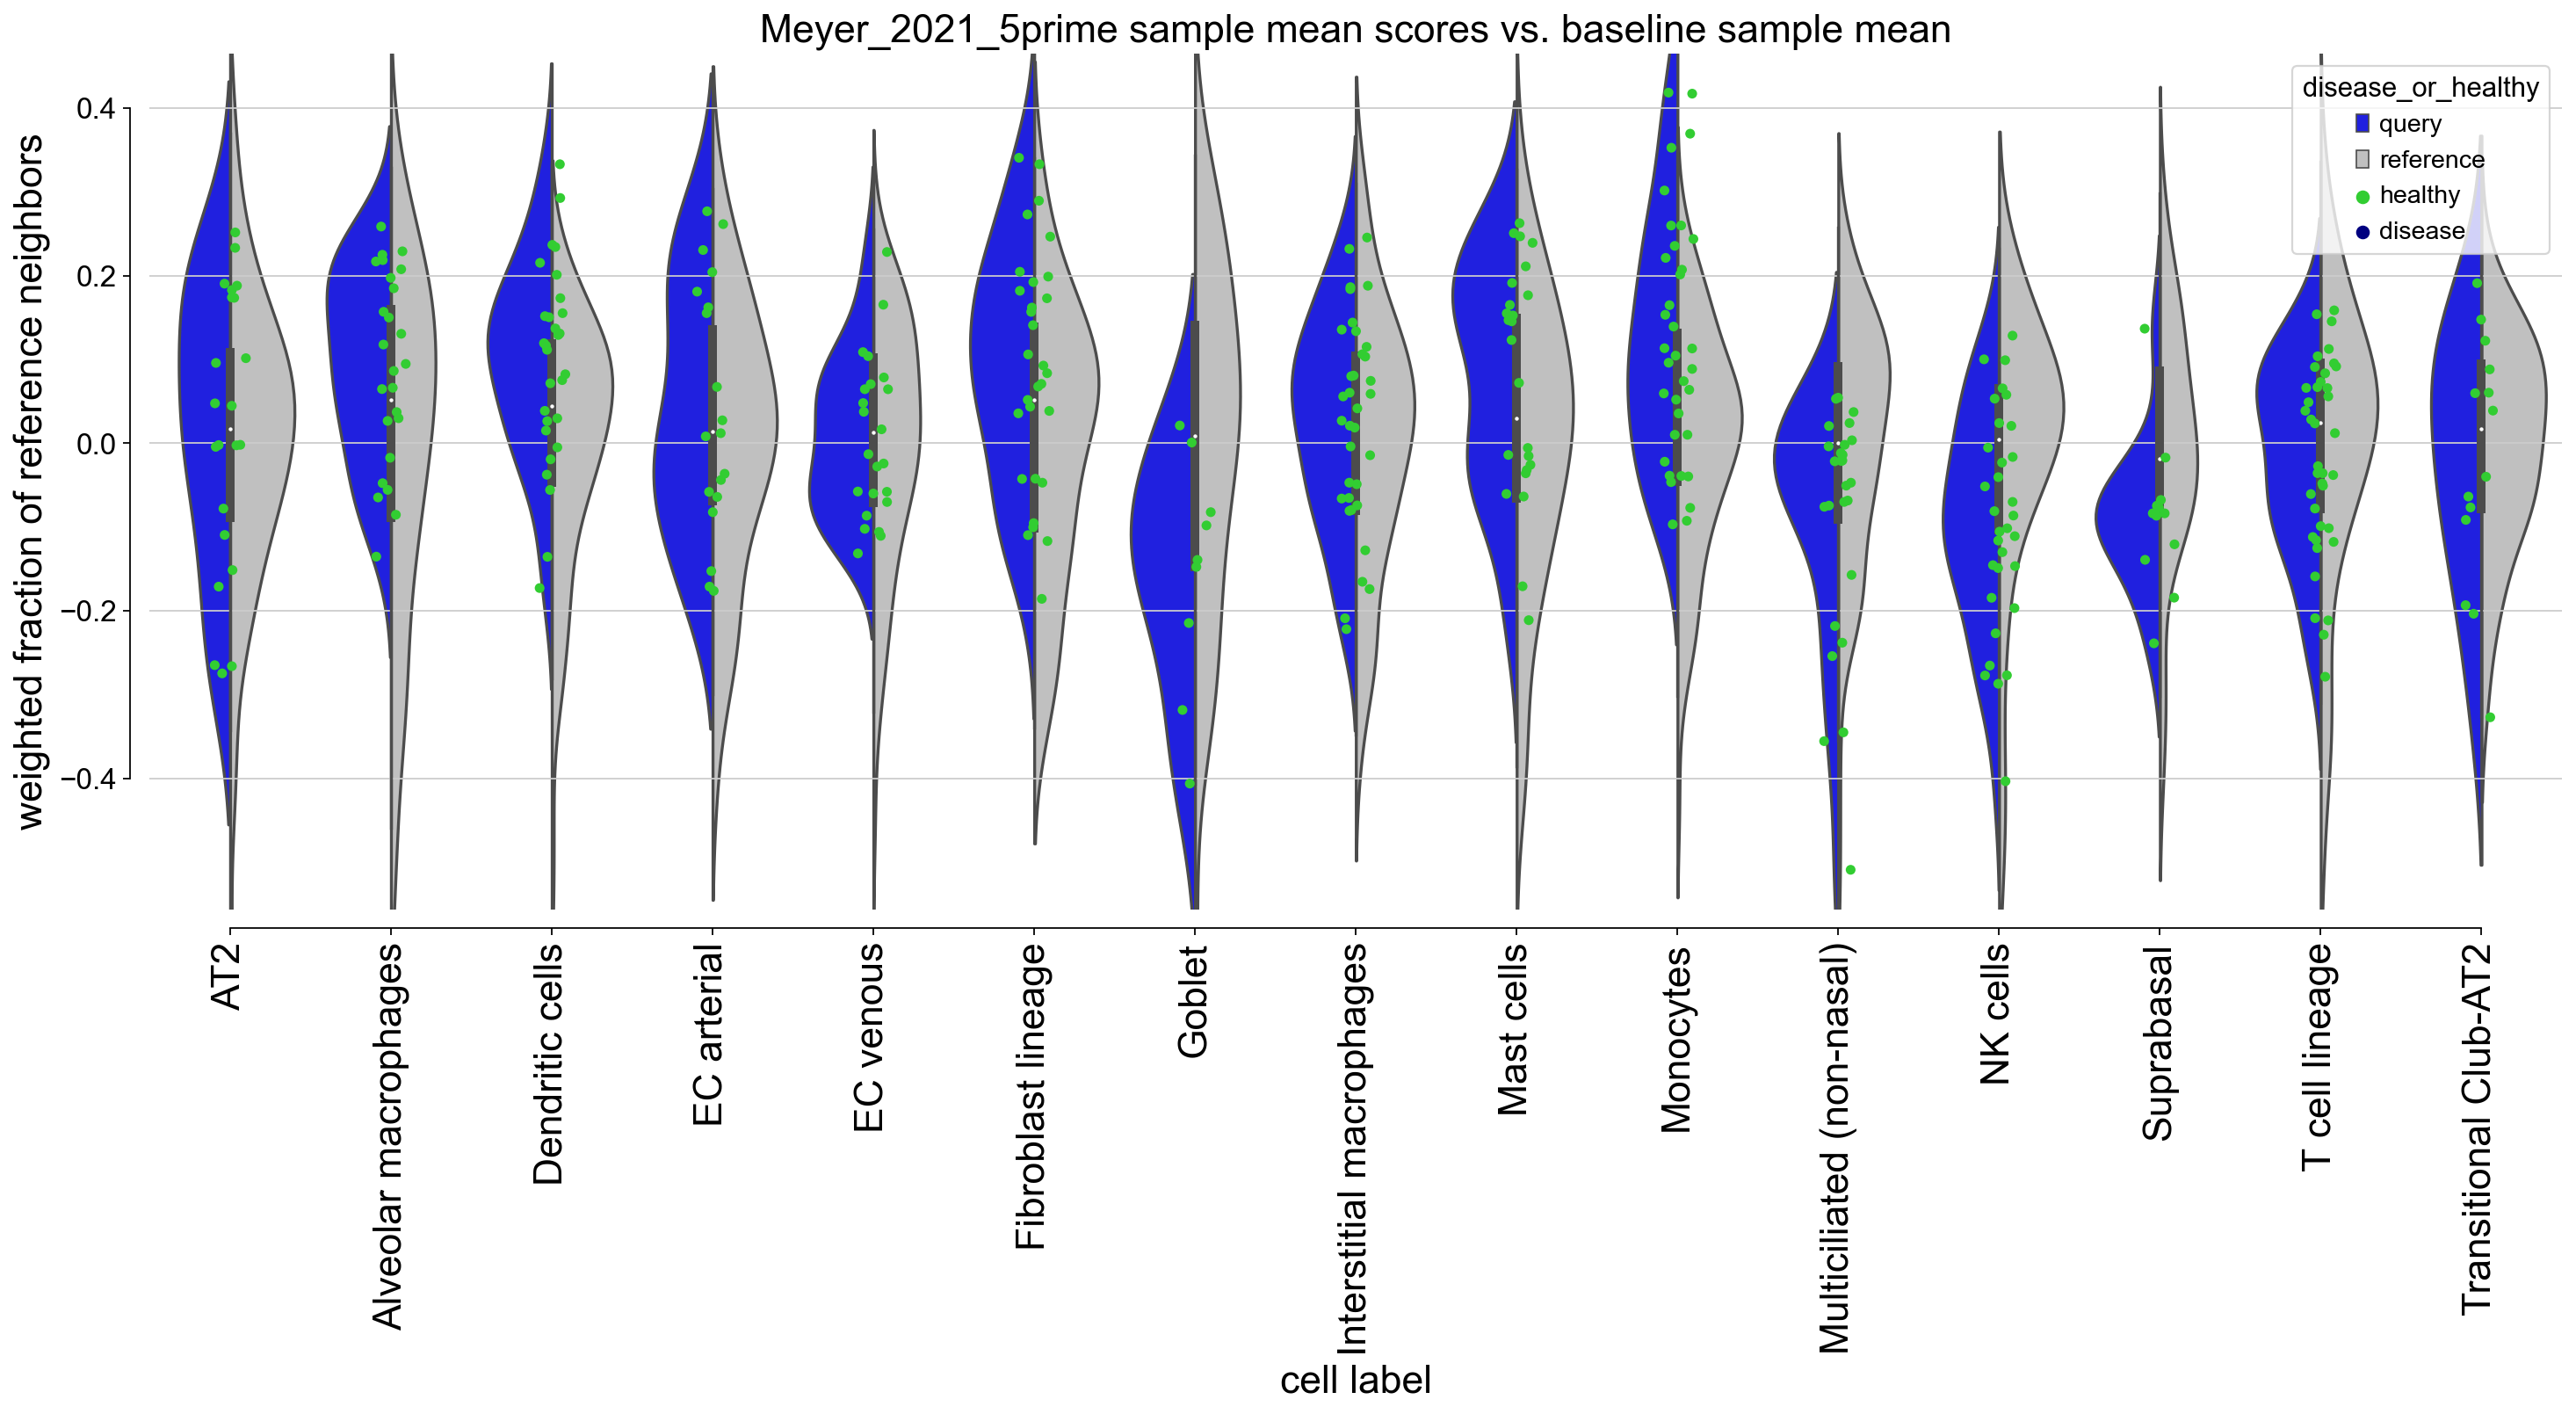

In [30]:
plotter.plot_baseline_comparison(
    adata,
    query_color,
    ident,
    disease=True,
    save=True,
    violin=True,
    #sample_filter=report,
    transform = os.path.join(RESULTS_DIR, 'transformation.csv')
)